# 10 — KU Leuven-to-synthetic transfer stress test

This notebook documents a controlled transfer experiment. A model is trained on the authorised KU Leuven dataset and applied unchanged to the synthetic Indian-university planner data. The purpose is to expose measurement shift and calibration risk; this is not evidence that the synthetic data represents real students.

Only the shared early-engagement contract is used: `course_id`, `activity_count`, `active_day_count`, `content_count`, `session_count`, `mean_daily_activity`, and `has_activity`. Synthetic sleep, screen time, wellbeing, CGPA, attendance, recommendations, and planner-only fields are intentionally excluded because KU Leuven does not provide directly comparable measurements.

## Protocol and interpretation

The source protocol trains on KU Leuven 1819, selects the model and operating threshold on 1920, refits the selected model on 1819+1920, and applies that unchanged fitted model to synthetic enrollment rows. Cutoffs of 30, 60, and 90 days represent staged evidence windows: earlier cutoffs preserve intervention time, while later cutoffs provide more observations. The synthetic label is `target_risk = 1 - passed`.

Metrics are interpreted together. ROC-AUC and PR-AUC measure ranking, balanced accuracy gives equal weight to both classes, F1 reflects precision-recall balance, Brier score measures probability error, and the confusion matrix shows the operational consequence of the threshold. Accuracy is not sufficient because the synthetic risk prevalence is highly imbalanced.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd()
if not (repo_root / 'models').exists():
    repo_root = repo_root.parent
metrics_path = repo_root / 'models' / 'metrics' / 'cross_dataset_transfer_metrics.json'
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
evaluations = metrics['evaluations']
cutoffs = [str(value) for value in metrics['cutoffs_days']]
print(f'Metrics artifact: {metrics_path}')
print(metrics['interpretation'])

Metrics artifact: D:\AI PROJECTS\C++\Smart-Study-Planner\models\metrics\cross_dataset_transfer_metrics.json
development transfer stress test; not real-world validation and not evidence that synthetic data is realistic


In [2]:
summary = pd.DataFrame({
    'cutoff_days': [int(c) for c in cutoffs],
    'source_model': [evaluations[c]['source_model'] for c in cutoffs],
    'rows': [evaluations[c]['n_synthetic_rows'] for c in cutoffs],
    'risk_rate': [evaluations[c]['target_positive_rate'] for c in cutoffs],
    'roc_auc': [evaluations[c]['roc_auc'] for c in cutoffs],
    'pr_auc': [evaluations[c]['pr_auc'] for c in cutoffs],
    'balanced_accuracy': [evaluations[c]['balanced_accuracy'] for c in cutoffs],
    'f1': [evaluations[c]['f1'] for c in cutoffs],
    'brier_score': [evaluations[c]['brier_score'] for c in cutoffs],
    'ece': [evaluations[c]['expected_calibration_error'] for c in cutoffs],
})
display(summary.style.format({
    'risk_rate': '{:.2%}', 'roc_auc': '{:.4f}', 'pr_auc': '{:.4f}',
    'balanced_accuracy': '{:.4f}', 'f1': '{:.4f}', 'brier_score': '{:.4f}', 'ece': '{:.4f}'
}))
print('Feature contract:', metrics['feature_mapping'])

,cutoff_days,source_model,rows,risk_rate,roc_auc,pr_auc,balanced_accuracy,f1,brier_score,ece
0,30,logistic_regression,12000,1.27%,0.5067,0.0128,0.5000,0.0250,0.5968,0.7644
1,60,logistic_regression,12000,1.27%,0.5133,0.0130,0.5000,0.0250,0.6660,0.8084
2,90,logistic_regression,12000,1.27%,0.5133,0.0130,0.5000,0.0250,0.6915,0.8240


Feature contract: {'activity_count': 'KU Leuven LMS actions; synthetic study-session rows', 'active_day_count': 'distinct observed event dates', 'content_count': 'distinct LMS content; synthetic distinct topic IDs', 'session_count': 'distinct LMS sessions; synthetic distinct study sessions', 'mean_daily_activity': 'activity_count divided by active_day_count', 'has_activity': 'one when activity_count is positive'}


The risk prevalence is 1.27% in the generated target slice. The near-0.5 ROC-AUC and near-prevalence PR-AUC indicate that the source model does not rank synthetic risk usefully. The calibration error is large because the source probabilities are concentrated near 0.78–0.84 while the observed synthetic risk rate is 1.27%.

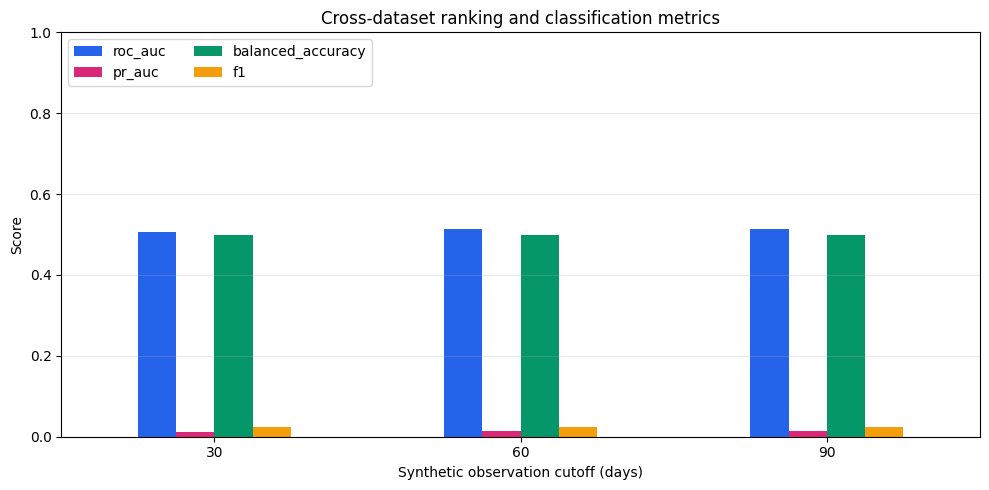

In [3]:
plot_metrics = summary.set_index('cutoff_days')[['roc_auc', 'pr_auc', 'balanced_accuracy', 'f1']]
ax = plot_metrics.plot(kind='bar', figsize=(10, 5), color=['#2563eb', '#db2777', '#059669', '#f59e0b'])
ax.set_title('Cross-dataset ranking and classification metrics')
ax.set_xlabel('Synthetic observation cutoff (days)')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

The metrics remain close to random-ranking performance at all three cutoffs. Increasing the observation window does not repair the transfer problem because the primary issue is not simply too little synthetic history; the event definitions, distributions, label prevalence, and model calibration differ between datasets.

C:\Users\RAFISO~1\AppData\Local\Temp\ipykernel_12196\3256199448.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


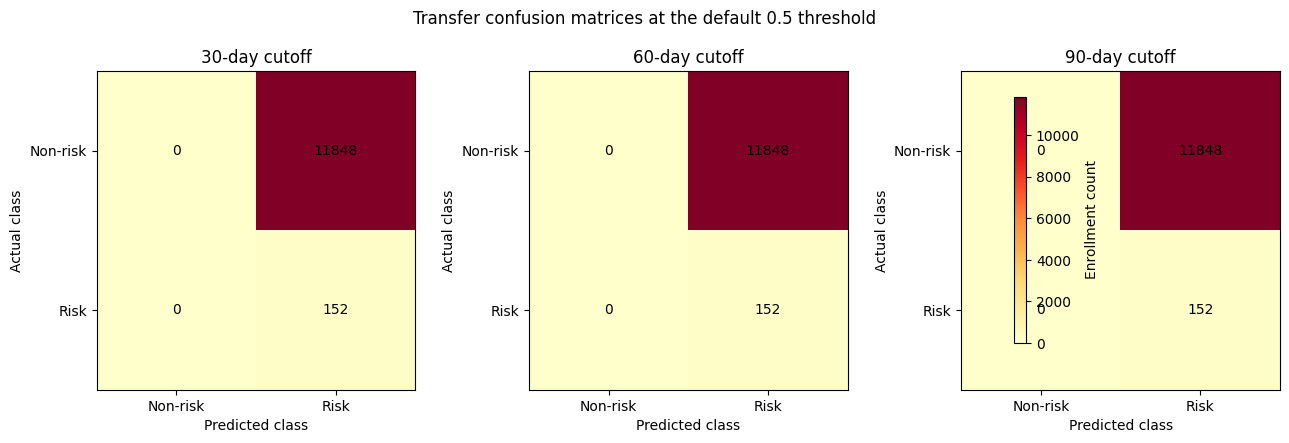

In [4]:
fig, axes = plt.subplots(1, len(cutoffs), figsize=(13, 4))
if len(cutoffs) == 1:
    axes = [axes]
for ax, cutoff in zip(axes, cutoffs):
    cm = np.asarray(evaluations[cutoff]['confusion_matrix'])
    image = ax.imshow(cm, cmap='YlOrRd')
    ax.set_title(f'{cutoff}-day cutoff')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
    ax.set_xticks([0, 1], ['Non-risk', 'Risk'])
    ax.set_yticks([0, 1], ['Non-risk', 'Risk'])
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, int(value), ha='center', va='center', color='black')
fig.colorbar(image, ax=axes, shrink=0.8, label='Enrollment count')
fig.suptitle('Transfer confusion matrices at the default 0.5 threshold', y=1.02)
plt.tight_layout()
plt.show()

Every synthetic enrollment is predicted as risk, producing 11,848 false positives and 152 true positives, with no true negatives or false negatives. Recall is therefore 1.0 but precision is only 1.27%; this is an unusable support policy. The identical matrix at the source validation threshold confirms that changing only the threshold within the source policy does not solve the target-domain mismatch.

### Formal conclusion

The source model does not transfer usefully to the current synthetic dataset. The result is a reproducible warning about measurement shift and calibration, not a claim that the synthetic generator is valid or invalid in all respects. The project still needs target-domain calibration, consented institutional data, prospective outcomes, subgroup review, and intervention evaluation before deployment.